# ASL Dataset Preview

This notebook checks the dataset structure and displays random labelled ASL sign samples.

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix

In [12]:
DATASET_PATH = "dataset/asl_dataset"

print("Dataset path:", DATASET_PATH)
print("Path exists:", os.path.exists(DATASET_PATH))

Dataset path: dataset/asl_dataset
Path exists: True


In [14]:
classes = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Number of classes:", len(classes))
print("Classes:", classes)

Number of classes: 36
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [15]:
from pathlib import Path
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = [
    path for path in Path(DATASET_PATH).rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

class_counts = Counter(path.parent.name for path in image_paths)

print("Total images:", len(image_paths))
print("\nImages in each class:")

for class_name in sorted(class_counts):
    print(f"{class_name}: {class_counts[class_name]}")

Total images: 2515

Images in each class:
0: 70
1: 70
2: 70
3: 70
4: 70
5: 70
6: 70
7: 70
8: 70
9: 70
a: 70
b: 70
c: 70
d: 70
e: 70
f: 70
g: 70
h: 70
i: 70
j: 70
k: 70
l: 70
m: 70
n: 70
o: 70
p: 70
q: 70
r: 70
s: 70
t: 65
u: 70
v: 70
w: 70
x: 70
y: 70
z: 70


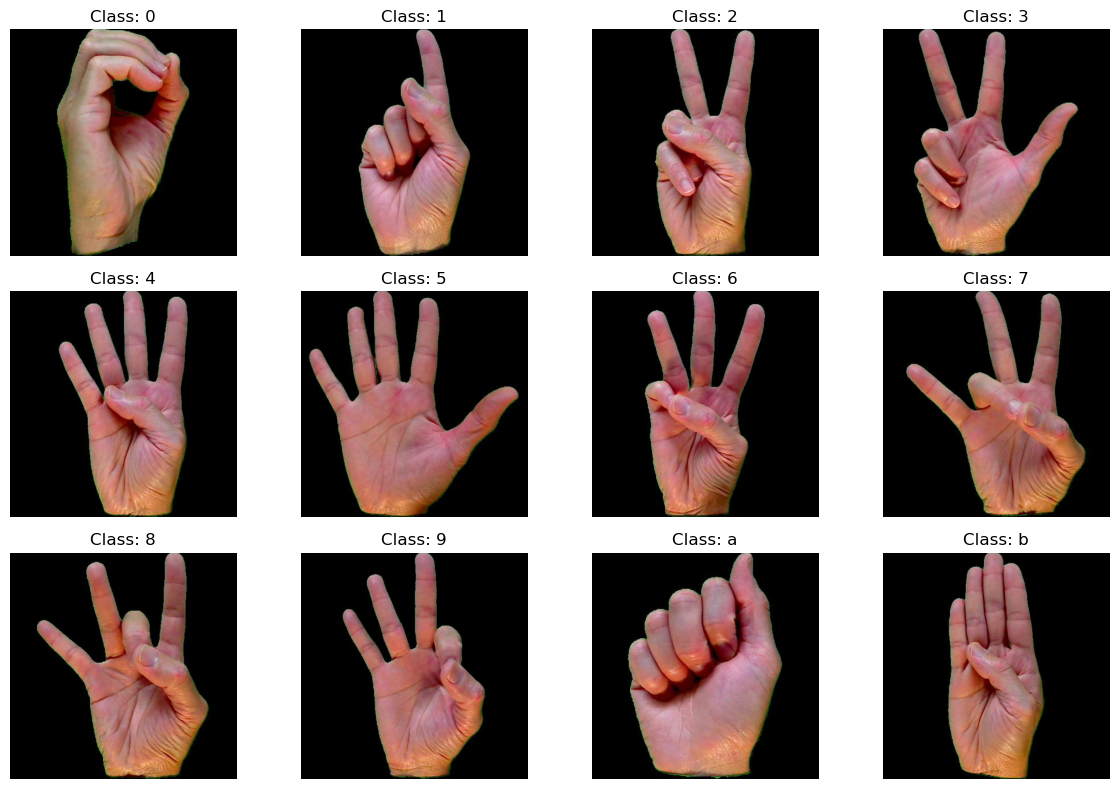

In [16]:
plt.figure(figsize=(12, 8))

sample_classes = classes[:12]

for i, class_name in enumerate(sample_classes):

    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if not image_files:
        continue

    image_path = os.path.join(class_path, image_files[0])

    image = plt.imread(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"Class: {class_name}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
IMG_SIZE = 64
BATCH_SIZE = 32

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 64
Batch size: 32


In [18]:
datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.2
)

In [19]:
train_data = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

Found 2012 images belonging to 36 classes.


In [20]:
validation_data = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

Found 503 images belonging to 36 classes.


In [21]:
class_indices = train_data.class_indices

print("Class mapping:")
print(class_indices)

Class mapping:
{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9, 'a': 10, 'b': 11, 'c': 12, 'd': 13, 'e': 14, 'f': 15, 'g': 16, 'h': 17, 'i': 18, 'j': 19, 'k': 20, 'l': 21, 'm': 22, 'n': 23, 'o': 24, 'p': 25, 'q': 26, 'r': 27, 's': 28, 't': 29, 'u': 30, 'v': 31, 'w': 32, 'x': 33, 'y': 34, 'z': 35}


In [22]:
index_to_class = {
    value: key for key, value in class_indices.items()
}

print("\nIndex to class mapping:")
print(index_to_class)


Index to class mapping:
{0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'a', 11: 'b', 12: 'c', 13: 'd', 14: 'e', 15: 'f', 16: 'g', 17: 'h', 18: 'i', 19: 'j', 20: 'k', 21: 'l', 22: 'm', 23: 'n', 24: 'o', 25: 'p', 26: 'q', 27: 'r', 28: 's', 29: 't', 30: 'u', 31: 'v', 32: 'w', 33: 'x', 34: 'y', 35: 'z'}


In [23]:
model = models.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),

    # Reduce overfitting
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(len(classes), activation="softmax")
])

In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 36)                  │           4,644 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,629,796 (6.22 MB)

 Trainable params: 1,629,796 (6.22 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [28]:
EPOCHS = 10

history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 200ms/step - accuracy: 0.3743 - loss: 2.2977 - val_accuracy: 0.8171 - val_loss: 0.6182
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step - accuracy: 0.7744 - loss: 0.7627 - val_accuracy: 0.8529 - val_loss: 0.4549
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 162ms/step - accuracy: 0.8519 - loss: 0.4516 - val_accuracy: 0.8926 - val_loss: 0.3699
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - accuracy: 0.9001 - loss: 0.3041 - val_accuracy: 0.8728 - val_loss: 0.3319
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 136ms/step - accuracy: 0.9076 - loss: 0.2651 - val_accuracy: 0.8748 - val_loss: 0.4291
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 143ms/step - accuracy: 0.9304 - loss: 0.1800 - val_accuracy: 0.8767 - val_loss: 0.4509
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 146ms/step - accuracy: 0.9359 - loss: 0.1902 - val_accuracy: 0.8708 - val_loss: 0.4659


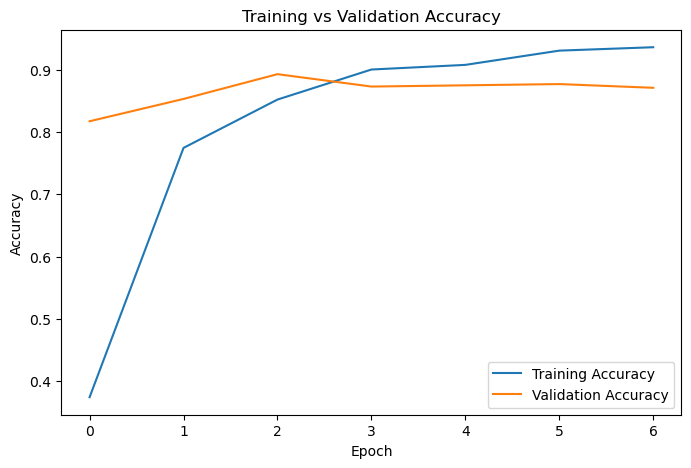

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

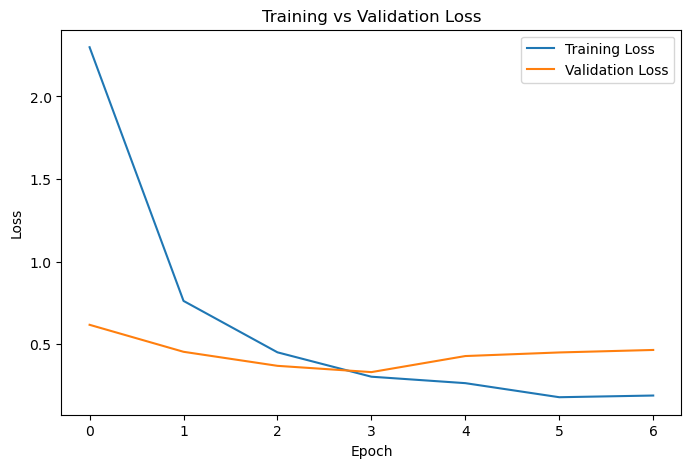

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

In [32]:
validation_loss, validation_accuracy = model.evaluate(validation_data)

print(f"Validation Loss: {validation_loss:.4f}")
print(f"Validation Accuracy: {validation_accuracy * 100:.2f}%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - accuracy: 0.8728 - loss: 0.3319
Validation Loss: 0.3319
Validation Accuracy: 87.28%


In [33]:
validation_data.reset()

predictions = model.predict(validation_data)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = validation_data.classes

class_names = list(validation_data.class_indices.keys())

print(
    classification_report(
        true_classes,
        predicted_classes,
        target_names=class_names,
        zero_division=0
    )
)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step
              precision    recall  f1-score   support

           0       0.56      0.64      0.60        14
           1       0.82      1.00      0.90        14
           2       0.57      0.93      0.70        14
           3       0.93      1.00      0.97        14
           4       1.00      1.00      1.00        14
           5       1.00      1.00      1.00        14
           6       1.00      0.36      0.53        14
           7       1.00      0.86      0.92        14
           8       1.00      1.00      1.00        14
           9       1.00      1.00      1.00        14
           a       1.00      0.57      0.73        14
           b       1.00      1.00      1.00        14
           c       1.00      1.00      1.00        14
           d       1.00      1.00      1.00        14
           e       1.00      1.00      1.00        14
           f       1.00      1.00      1.00        14
           g       1.00      1.00      1

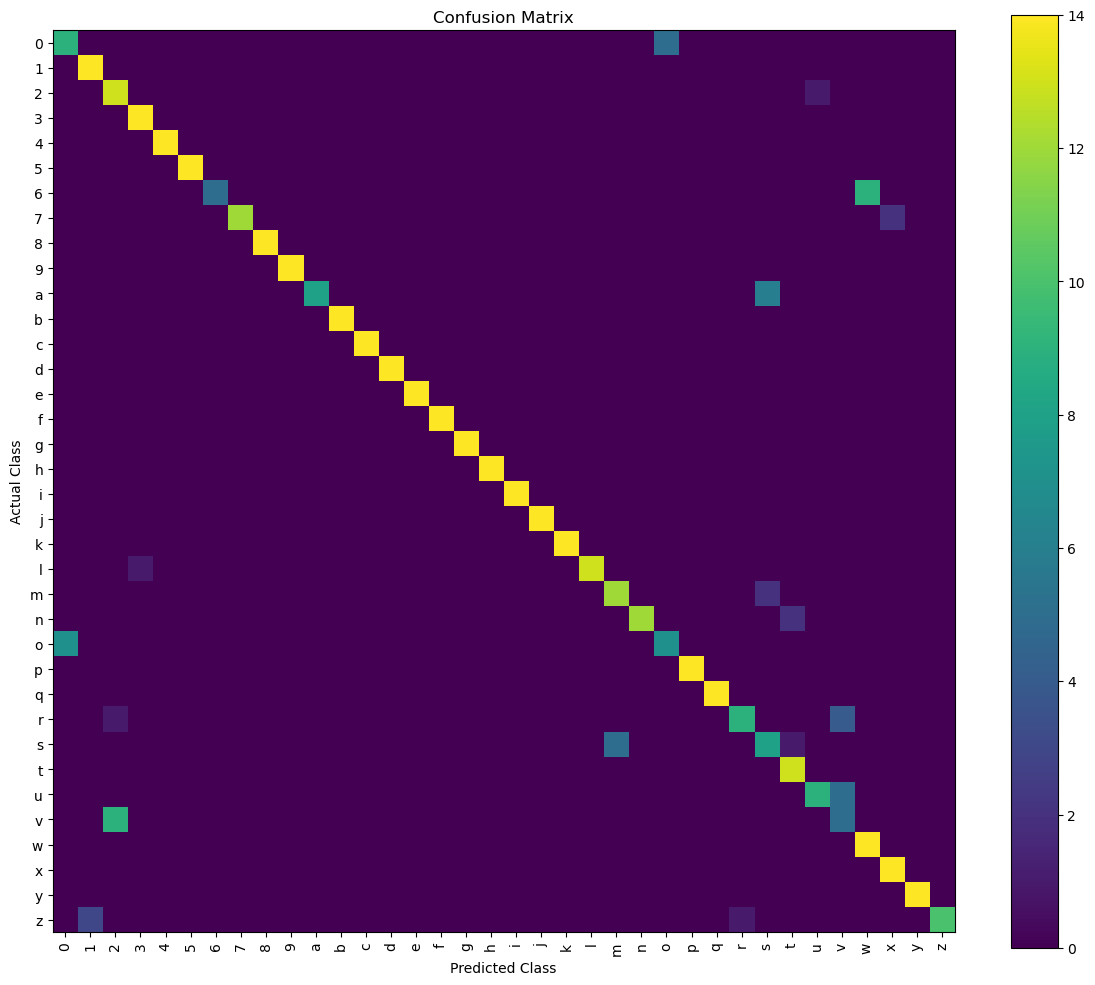

In [34]:
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

plt.figure(figsize=(12, 10))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.colorbar()

plt.tight_layout()
plt.show()

In [35]:
MODEL_PATH = "asl_cnn_phase1.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print("Saved as:", MODEL_PATH)

Model saved successfully!
Saved as: asl_cnn_phase1.keras


In [36]:
model = tf.keras.models.load_model("asl_cnn_phase1.keras")

print("Phase 1 ASL model loaded successfully!")

Phase 1 ASL model loaded successfully!


In [40]:
from IPython.display import display
import ipywidgets as widgets

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False
)

display(upload)

FileUpload(value=(), accept='image/*', description='Upload')

In [42]:
print(upload.value)


({'name': 'Screenshot 2026-09-02 172106.png', 'type': 'image/png', 'size': 103131, 'content': <memory at 0x0000020B20249780>, 'last_modified': datetime.datetime(2026, 9, 2, 11, 51, 6, 216000, tzinfo=datetime.timezone.utc)},)


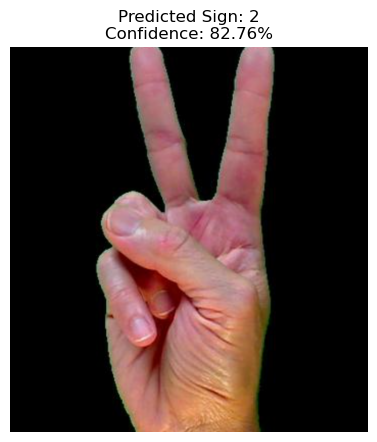

In [44]:
from PIL import Image
import io

if upload.value:

    # Get the uploaded file
    uploaded_file = upload.value[0]

    # Read image
    image = Image.open(
        io.BytesIO(uploaded_file["content"])
    ).convert("RGB")

    # Resize image
    image_resized = image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    # Convert to NumPy array
    image_array = np.array(image_resized)

    # Normalize pixel values
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Predict
    prediction = model.predict(
        image_array,
        verbose=0
    )

    # Get predicted class
    predicted_index = np.argmax(prediction[0])
    predicted_class = index_to_class[predicted_index]

    # Get confidence
    confidence = prediction[0][predicted_index] * 100

    # Display image and result
    plt.figure(figsize=(5, 5))

    plt.imshow(image)
    plt.axis("off")

    plt.title(
        f"Predicted Sign: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.show()

else:
    print("Please upload an image first.")